In [1]:
#import nbimporter
#import CLN
%run ./CLN.ipynb

class CLN_Cylinder(CLN):
    def __init__(self, mode='E', a=0.01, sigma=1e6, mur=1):
        super().__init__(mode, a, sigma, mur)     
        self.C = CoordSys3D('', transformation='cylindrical')
        self.x = sp.symbols('r', positive=True)
        self.y = sp.symbols('\\theta',real=True)
        
        import scipy.special as sp_special
        self.namespace = {
                'besseli': lambda v, x: sp_special.iv(v, x),
                'sqrt': np.sqrt,
                'Pi': np.pi
            }
        if self.mode=='E': self.formulation=self.formulationE
        elif self.mode=='H': self.formulation=self.formulationH

    def solveAmpere_by_integration(self, Jz, Hs=0):
        x, a=self.x, self.a
        if self.mode=='E':
            H = sp.integrate(J * r, r) / r
            H.doit().cancel()
        elif self.mode=='H' :
            H = sp.integrate(J , r)
            H.doit().cancel()
        return H

    def solveAmpere(self, J, Hs=0):
        if self.by_integ: return self.solveAmpere_by_integration(J, Hs)
        #  Jz=1/r*d/dr(r*Ht)  -Jt=d/dr(Hz)  
        r, a=self.x, self.a
        H = sp.Function('H')(r)
        if self.mode=='E':
            eq=sp.Eq(sp.Derivative(r*H, r), r*J)
            H=sp.dsolve(eq, H, ics={H.subs(r, 0): 0}).rhs       
        elif self.mode=='H' :
            eq=sp.Eq(sp.Derivative(H, r), J)       
            H=sp.dsolve(eq, H, ics={H.subs(r, a): Hs}).rhs
        return H

    def solveFaraday_by_integration(self, Bt, Es=0):
        r= self.x
        a = self.a
        Ez = sp.integrate(Bt, r)
        Ez = Ez - Ez.subs(r, a) + Es
        Ez.doit().cancel()
        return Ez
 
    def solveFaraday(self, B, Es=0):
        if self.by_integ: return self.solveFaraday_by_integration(B, Es)
        r, a=self.x, self.a
        #  -dEz / dx = -s * By  
        E = sp.Function('Ez')(r)
        if self.mode=='E':
            eq=sp.Eq(sp.Derivative(E, r), B)
            E=sp.dsolve(eq, E, ics={E.subs(r, a): Es}).rhs
        elif self.mode=='H':
            eq=sp.Eq(sp.Derivative(r*E, r), r*B)
            E=sp.dsolve(eq, E, ics={E.subs(r, 0): 0}).rhs
        return E

    def Vintegrate(self, integrand):
        r= self.x
        a = self.a
        return sp.integrate(integrand * r, (r, 0, a)) / a


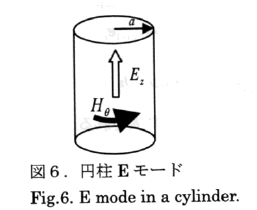

In [2]:
def formulationA(self, output=True):
    if output:
        display(Markdown("# ***** E mode in a cylinder *****"))
    """マクスウェル方程式からの自動導出と解析解・インピーダンスの算出（ステップごとのMarkdown表示付き）"""
    r, a, s, sigma, mu, Es = self.x, self.a, self.s, self.sigma, self.mu, self.Es
    C = self.C

    # ステップ1: ベクトルポテンシャル A と磁束密度 B, 磁界 H の定義
    Az_c = sp.Function('Az')(C.r)
    A = Az_c * C.k
    B = sp.vector.curl(A)
    H = B / mu
    if output:
        display(Markdown("---"))
        display(Markdown("### ** 磁束密度 $\\mathbf{B}$ と磁界 $\\mathbf{H}$ の定義**"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{A}} = {sp.latex(A)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{B}} = \\nabla \\times \\mathbf{{A}} = {sp.latex(B)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{H}} = \\frac{{\\mathbf{{B}}}}{{\\mu}} = {sp.latex(H)} \\end{{equation}}"))

    # ステップ2: 磁界の回転（curl H）の展開
    curl_H = sp.vector.curl(H).doit()
    if output:
        display(Markdown("---"))
        display(Markdown("### ** 磁界の回転 $\\nabla \\times \\mathbf{H}$ の展開**"))
        display(Markdown(f"\\begin{{equation}} \\nabla \\times \\mathbf{{H}} = {sp.latex(curl_H)} \\end{{equation}}"))

    # ステップ3: マクスウェル方程式（軸方向成分）の構築
    eq_maxwell_C = sp.Eq(curl_H.dot(C.k), (-sigma * s * A).dot(C.k))
    if output:
        display(Markdown("---"))
        display(Markdown("### ** マクスウェル方程式（z方向成分）**"))
        display(Markdown(f"\\begin{{equation}} {sp.latex(eq_maxwell_C)} \\end{{equation}}"))

    # ステップ4: ベッセル型標準形への自動整理
    Az_r = sp.Function('Az')(r)
    eq_z_standard = sp.Eq(
        sp.simplify(-eq_maxwell_C.lhs * mu).subs(C.r, r).subs(Az_c.subs(C.r, r), Az_r),
        sp.simplify(-eq_maxwell_C.rhs * mu).subs(C.r, r).subs(Az_c.subs(C.r, r), Az_r)
    )
    if output:
        display(Markdown("---"))
        display(Markdown("### ** 支配方程式　**"))
        display(Markdown(f"\\begin{{equation}} {sp.latex(eq_z_standard)} \\end{{equation}}"))

    # ステップ5: 境界条件を考慮した一般解の導出と電磁界・インピーダンスの算出
    #C1, C2 = sp.symbols('C1 C2')
    As = -Es / s

    alpha_val = sp.sqrt(mu) * sp.sqrt(s) * sp.sqrt(sigma)
    k = sp.Symbol('k', positive=True)

    general_sol = sp.dsolve(eq_z_standard, Az_r, ics={Az_r.subs(r, a): As})
    #sol = general_sol.rhs.subs({C2: 0})
    sol= self.remove_divergence(general_sol.rhs, 0)
    sol=sol.subs(alpha_val, k)

    Ez = -s * sol
    Ht = -1 / mu * sp.Derivative(sol, r).doit()
    Z_expr = (Ez / Ht).subs({r: a}).simplify()

    if output:
        display(Markdown("---"))
        display(Markdown("### ** 解析解（電場・磁界・表面インピーダンス）**"))
        display(Markdown(f"\\begin{{equation}} k = {sp.latex(alpha_val)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} E_z(r) = {sp.latex(Ez)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} H_\\theta(r) = {sp.latex(Ht)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} Z = {sp.latex(Z_expr)} \\end{{equation}}"))

    Z_exact_sym = Z_expr.subs(k, alpha_val).simplify()
    return Z_exact_sym
    
CLN_Cylinder.formulationE = formulationA


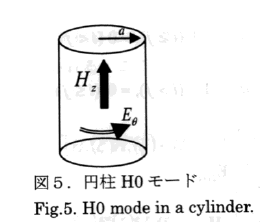

In [3]:
def formulationT(self, output=True):
    if output:
        display(Markdown("# ***** H mode in a cylinder *****"))
    """マクスウェル方程式からの自動導出と解析解・インピーダンスの算出（ステップごとのMarkdown表示付き）"""
    r, a, s, sigma, mu, Es = self.x, self.a, self.s, self.sigma, self.mu, self.Es
    C = self.C

    # ステップ1: ベクトルポテンシャル A と磁束密度 B, 磁界 H の定義
    Tz_c = sp.Function('Tz')(C.r)
    T=Tz_c *C.k
    H = T
    B = mu*H
    if output:
        display(Markdown("---"))
        display(Markdown("### **【磁束密度 $\\mathbf{B}$ と磁界 $\\mathbf{H}$ の定義**"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{T}} = {sp.latex(T)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{H}} = {sp.latex(H)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{B}} = \\mu  \\mathbf{{B}} = {sp.latex(B)} \\end{{equation}}"))


    # ステップ2: 磁界の回転（curl H）の展開
    curl_H = sp.vector.curl(H).doit()
    J=curl_H
    if output:
        display(Markdown("---"))
        display(Markdown("### **　磁界の回転 $\\nabla \\times \\mathbf{H}$ と電流密度　**"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{J}} = \\nabla \\times \\mathbf{{H}} = {sp.latex(curl_H)} \\end{{equation}}"))

    E=J/sigma
    curl_E=sp.vector.curl(E)
    eq_maxwell = sp.Eq(curl_E.dot(C.k), (- s * B).dot(C.k))
    if output:
        display(Markdown("---"))
        display(Markdown("### **【マクスウェル方程式（z方向成分）**"))
        display(Markdown(f"\\begin{{equation}}  \\nabla \\times \\mathbf{{E}}= {sp.latex(eq_maxwell)} \\end{{equation}}"))

    # ステップ4: ベッセル型標準形への自動整理
    Tz_r = sp.Function('Tz')(r)
    eq_z_standard = sp.Eq(
        sp.simplify(-eq_maxwell.lhs * sigma).subs(C.r, r).subs(Tz_c.subs(C.r, r), Tz_r),
        sp.simplify(-eq_maxwell.rhs * sigma).subs(C.r, r).subs(Tz_c.subs(C.r, r), Tz_r)
    )
    if output:
        display(Markdown("---"))
        display(Markdown("### **【支配方程式　**"))
        display(Markdown(f"\\begin{{equation}} {sp.latex(eq_z_standard)} \\end{{equation}}"))

    # ステップ5: 境界条件を考慮した一般解の導出と電磁界・インピーダンスの算出
    #C1, C2 = sp.symbols('C1 C2')
    Hs = 1

    alpha_val = sp.sqrt(mu) * sp.sqrt(s) * sp.sqrt(sigma)
    k = sp.Symbol('k', positive=True)

    general_sol = sp.dsolve(eq_z_standard, Tz_r, ics={Tz_r.subs(r, a): Hs})
    #sol = general_sol.rhs.subs({C2: 0})
    sol= self.remove_divergence(general_sol.rhs, 0)
    sol=sol.subs(alpha_val, k)

    Hz = sol
    Et = 1 / sigma * sp.Derivative(sol, r).doit()
    Z_expr = (Et / Hz).subs({r: a}).simplify()

    if output:
        display(Markdown("---"))
        display(Markdown("### **【解析解（電場・磁界・表面インピーダンス）**"))
        display(Markdown(f"\\begin{{equation}} k = {sp.latex(alpha_val)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} H_z(r) = {sp.latex(Hz)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} E_\\theta(r) = {sp.latex(Et)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} Z = {sp.latex(Z_expr)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mu_r =Z/(sa\\mu_0)  \\end{{equation}}"))

    self._Z_exact_sym = Z_expr.subs(k, alpha_val).simplify()
    return self._Z_exact_sym

CLN_Cylinder.formulationH = formulationT


# ***** E mode in a cylinder *****

---

### ** 磁束密度 $\mathbf{B}$ と磁界 $\mathbf{H}$ の定義**

\begin{equation} \mathbf{A} = \left(\operatorname{Az}{\left(\mathbf{{r}_{}} \right)}\right)\mathbf{\hat{k}_{}} \end{equation}

\begin{equation} \mathbf{B} = \nabla \times \mathbf{A} = \left(- \frac{d}{d \mathbf{{r}_{}}} \operatorname{Az}{\left(\mathbf{{r}_{}} \right)}\right)\mathbf{\hat{j}_{}} \end{equation}

\begin{equation} \mathbf{H} = \frac{\mathbf{B}}{\mu} = \left(- \frac{\frac{d}{d \mathbf{{r}_{}}} \operatorname{Az}{\left(\mathbf{{r}_{}} \right)}}{\mu}\right)\mathbf{\hat{j}_{}} \end{equation}

... (27 outputs left out)

<IPython.core.display.Math object>

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), 2*R_c + 1/(1/(6*R_c + 1/(1/(10*R_c + 1/(1/(14*R_c + 1/(1/(18*R_c) + 16/(L_c*s))) + 12/(L_c*s))) + 8/(L_c*s))) + 4/(L_c*s)))

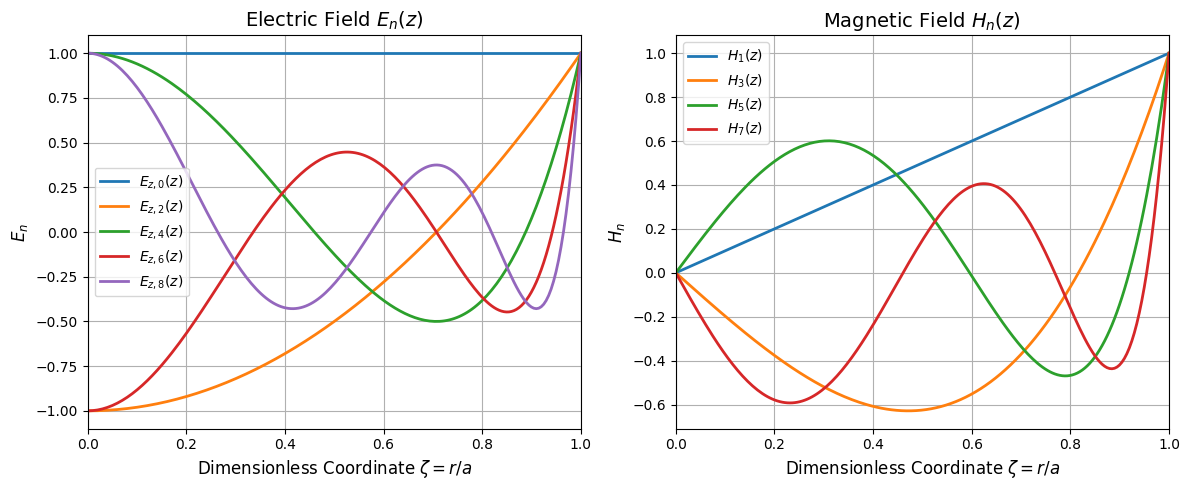

{a: 0.01, sigma: 1000000.0, mu: 4.0e-7*pi}


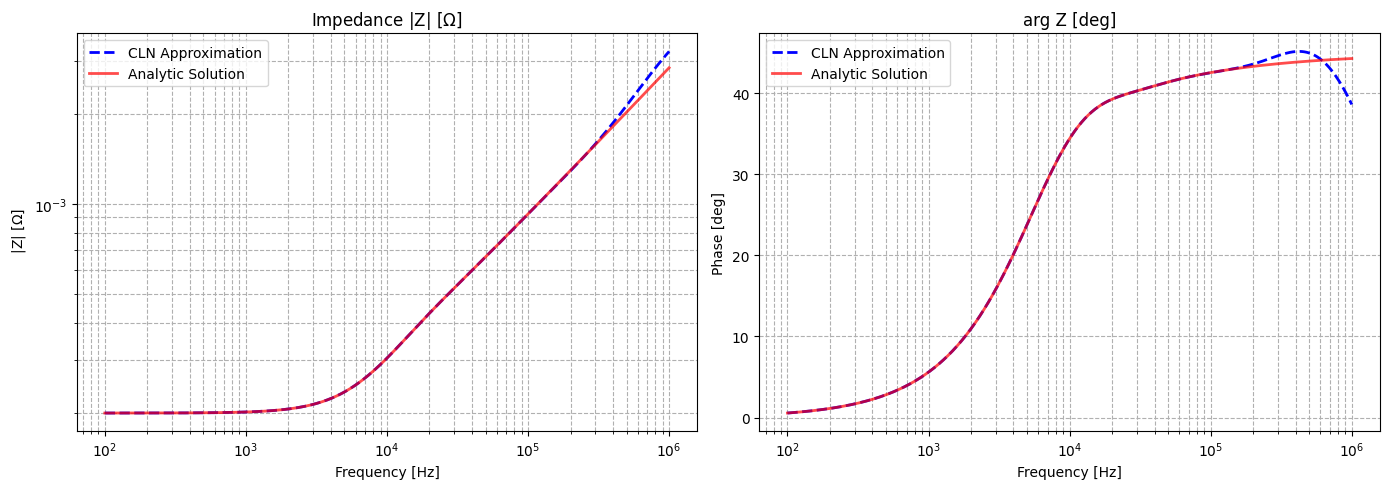

In [4]:
mode='E'
cln= CLN_Cylinder(mode)
if mode=='E': cln.formulationE()
else: cln.formulationH()
R, L, E, H, Z=cln.buildCLN('E_H', nmax=8)

cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)
cln.plot_EH(E, H)
cln.plot_Z(Z)

# ***** H mode in a cylinder *****

---

### **【磁束密度 $\mathbf{B}$ と磁界 $\mathbf{H}$ の定義**

\begin{equation} \mathbf{T} = \left(\operatorname{Tz}{\left(\mathbf{{r}_{}} \right)}\right)\mathbf{\hat{k}_{}} \end{equation}

\begin{equation} \mathbf{H} = \left(\operatorname{Tz}{\left(\mathbf{{r}_{}} \right)}\right)\mathbf{\hat{k}_{}} \end{equation}

\begin{equation} \mathbf{B} = \mu  \mathbf{B} = \left(\mu \operatorname{Tz}{\left(\mathbf{{r}_{}} \right)}\right)\mathbf{\hat{k}_{}} \end{equation}

... (28 outputs left out)

<IPython.core.display.Math object>

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), 1/(1/(4*R_c + 1/(1/(8*R_c + 1/(1/(12*R_c + 1/(1/(L_c*s/18 + 16*R_c) + 14/(L_c*s))) + 10/(L_c*s))) + 6/(L_c*s))) + 2/(L_c*s)))

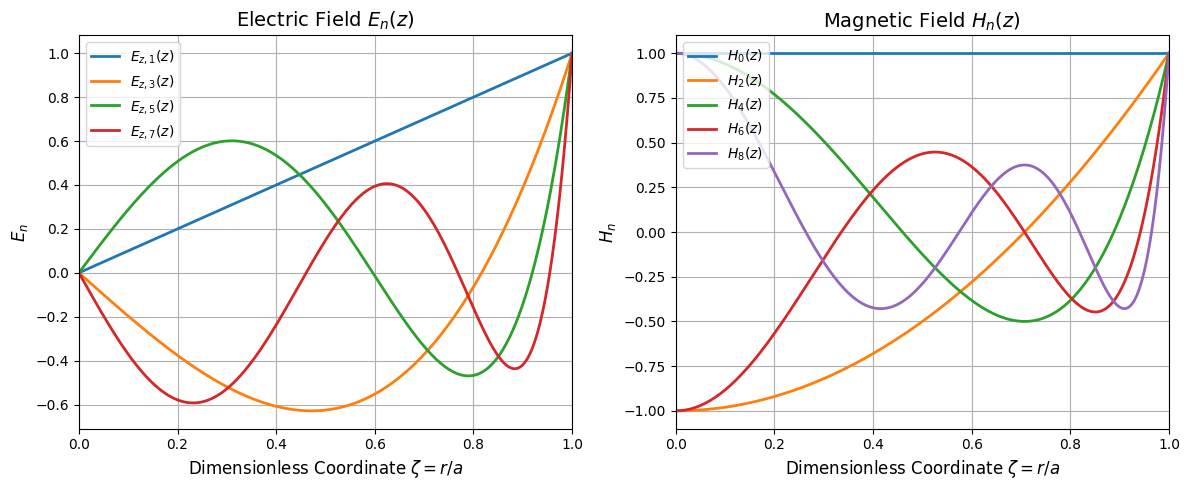

{a: 0.01, sigma: 1000000.0, mu: 4.0e-7*pi}


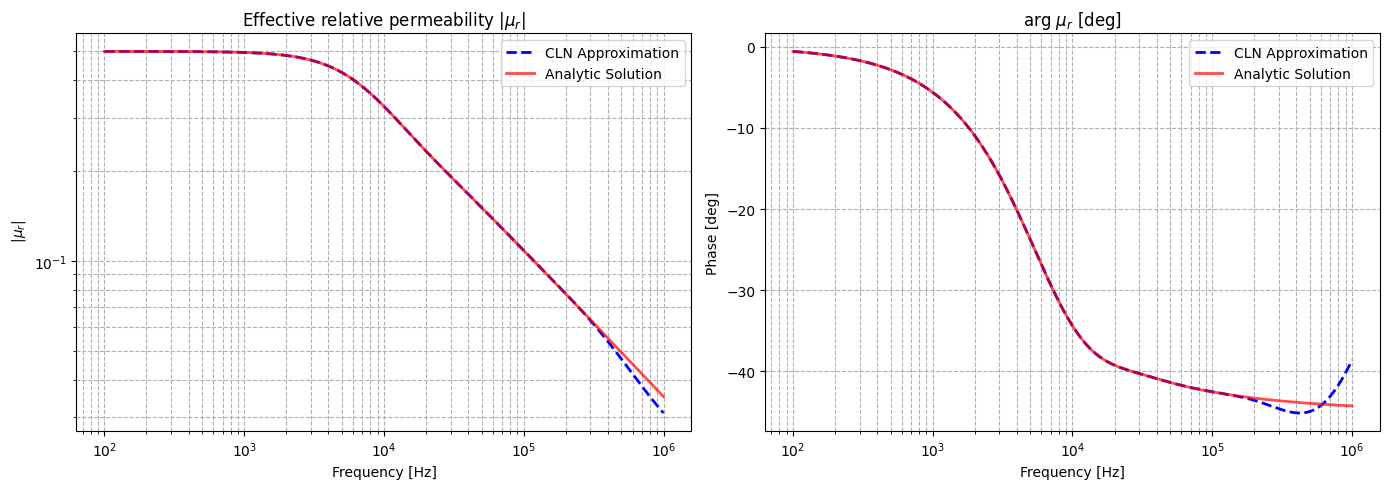

In [5]:
mode='H'
cln= CLN_Cylinder(mode)
if mode=='E': cln.formulationE()
else: cln.formulationH()
R, L, E, H, Z=cln.buildCLN('E_H', nmax=8)

cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)
cln.plot_EH(E, H)
cln.plot_Z(Z)

In [6]:
cln=CLN_Cylinder('H')
R, L, A, E, H, Z=cln.buildCLN('A', nmax=8)
cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)


### **電界モード $E_{n}(z)$  ( $\zeta = r/a$)**

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### **磁界モード $H_{n}(z)$   ( $\zeta = r/a$)**

... (6 outputs left out)

<IPython.core.display.Math object>

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), 1/(1/(4*R_c + 1/(1/(8*R_c + 1/(1/(12*R_c + 1/(1/(L_c*s/18 + 16*R_c) + 14/(L_c*s))) + 10/(L_c*s))) + 6/(L_c*s))) + 2/(L_c*s)))

In [7]:
cln=CLN_Cylinder('H')
R, L, T, E, H, Z=cln.buildCLN('T',nmax=8)
cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)


### **電界モード $E_{n}(z)$  ( $\zeta = r/a$)**

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### **磁界モード $H_{n}(z)$   ( $\zeta = r/a$)**

... (6 outputs left out)

<IPython.core.display.Math object>

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), 1/(1/(4*R_c + 1/(1/(8*R_c + 1/(1/(12*R_c + 1/(1/(L_c*s/18 + 16*R_c) + 14/(L_c*s))) + 10/(L_c*s))) + 6/(L_c*s))) + 2/(L_c*s)))